In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('food_delivery_orders.csv')
df = df.drop_duplicates()
df['order_date'] = pd.to_datetime(df['order_date'])
df['city'] = df['city'].astype('category')
df['restaurant_category'] = df['restaurant_category'].astype('category')
df['cuisine'] = df['cuisine'].astype('category')
df = df.dropna()
df.to_csv('food_delivery_orders_cleaned.csv', index=False)
df.head()

,order_date,city,restaurant_category,cuisine,order_value,discount_percent,delivery_time_min,rating,profit_per_order
0,2023-01-01,Karachi,Fine Dining,Continental,2768.0,25.0,36.2,4.5,95.0
1,2023-01-01,Karachi,Fine Dining,Steakhouse,4979.0,44.8,23.3,4.8,-437.0
2,2023-01-01,Karachi,Cloud Kitchen,Indian,4008.0,11.9,39.6,4.2,618.0
3,2023-01-01,Islamabad,Fine Dining,Steakhouse,3260.0,8.3,35.8,4.5,423.0
4,2023-01-01,Karachi,Fast Food,Pizza,435.0,13.5,29.4,4.8,53.0


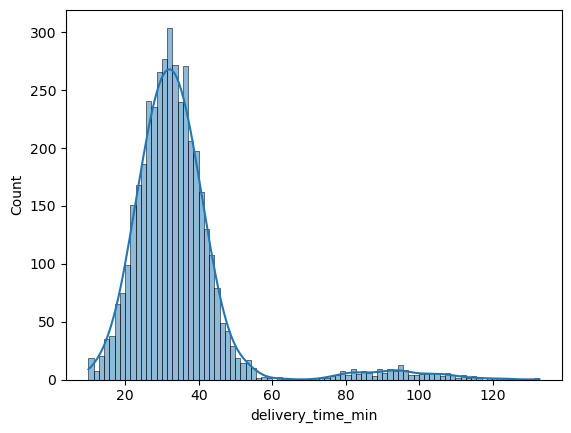

skew: 2.8770611473024483
mean: 34.541809523809526 median: 32.5


In [3]:
#task1
sns.histplot(df['delivery_time_min'], kde=True)
plt.show()

print('skew:', df['delivery_time_min'].skew())
print('mean:', df['delivery_time_min'].mean(), 'median:', df['delivery_time_min'].median())
# Median is the more honest number and since distribution is strongly right-skewed (skew ~2.9) and mean >> median.

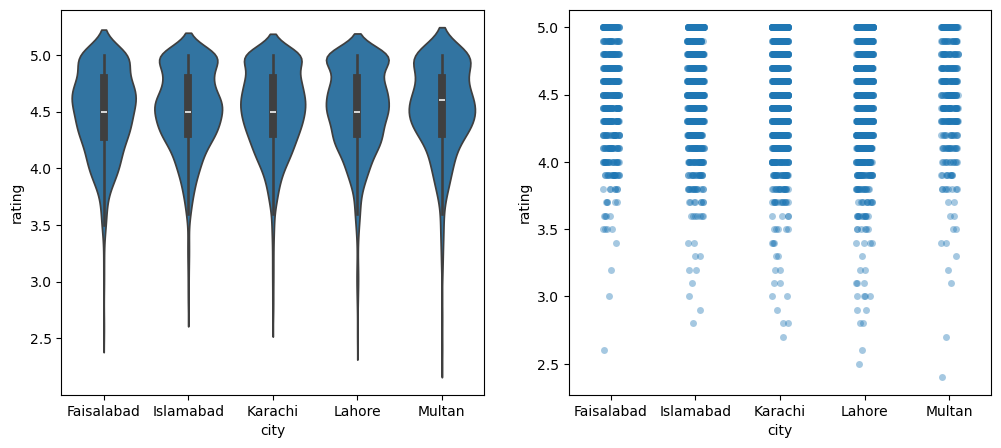

city
Faisalabad    0.384213
Islamabad     0.373966
Karachi       0.380484
Lahore        0.396755
Multan        0.400584
Name: rating, dtype: float64


C:\Users\VICTUS\AppData\Local\Temp\ipykernel_20144\139803490.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('city')['rating'].std())


In [4]:
#task2
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.violinplot(data=df, x='city', y='rating', ax=ax[0])
sns.stripplot(data=df, x='city', y='rating', jitter=True, alpha=0.4, ax=ax[1])
plt.show()

print(df.groupby('city')['rating'].std())
# Multan shows the most inconsistent experience: it has the highest rating std despite a similar mean, i.e. wide spread rather than a low average.

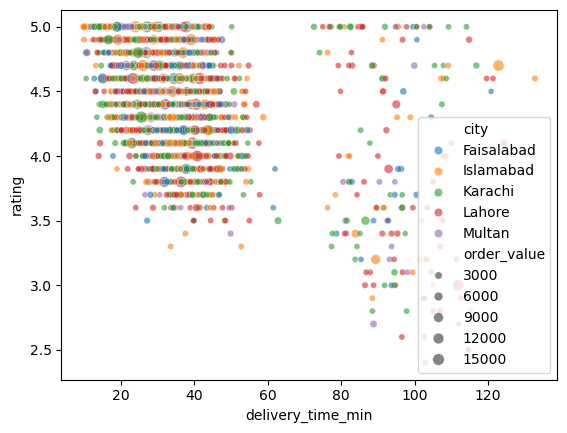

In [11]:
#task3
sns.scatterplot(data=df, x='delivery_time_min', y='rating', hue='city', size='order_value', alpha=0.6)
plt.show()
# High order_value points (larger markers) cluster at lower delivery_time_min and higher rating, so high-value orders tend to get faster, better-rated delivery.

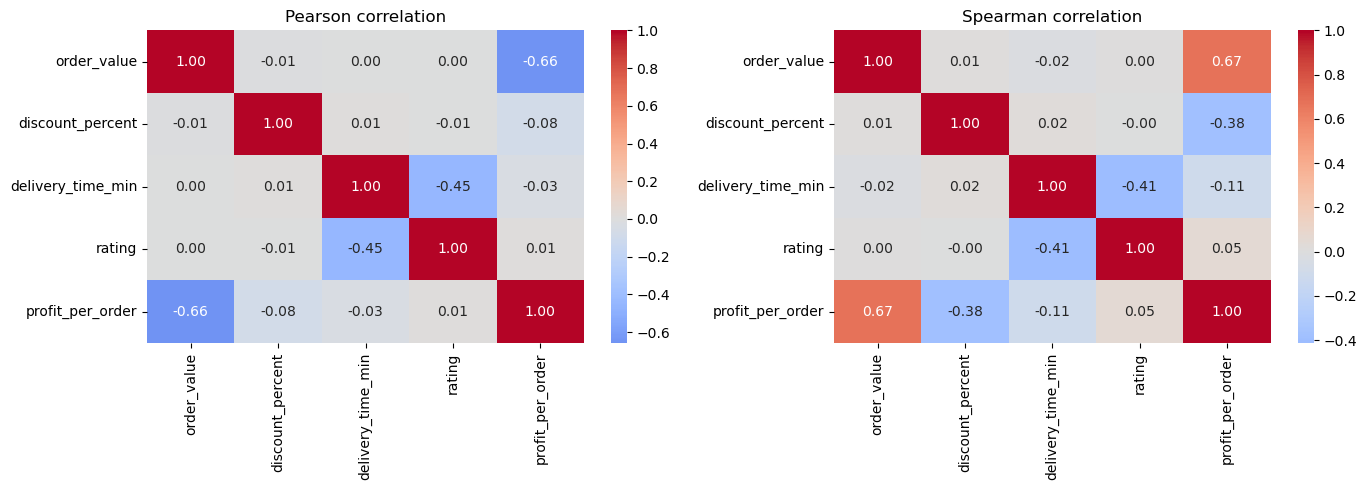

('order_value', 'profit_per_order')


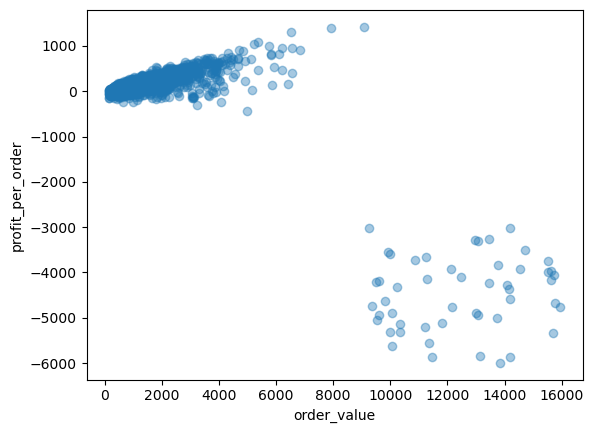

                  order_value  profit_per_order
order_value          1.000000          0.609515
profit_per_order     0.609515          1.000000


In [12]:
#task4
num_cols = ['order_value', 'discount_percent', 'delivery_time_min', 'rating', 'profit_per_order']
pearson_corr = df[num_cols].corr(method='pearson')
spearman_corr = df[num_cols].corr(method='spearman')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pearson_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0])
ax[0].set_title('Pearson correlation')
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1])
ax[1].set_title('Spearman correlation')
plt.tight_layout()
plt.show()

diff = (pearson_corr - spearman_corr).abs()
diff_vals = diff.values.copy()
np.fill_diagonal(diff_vals, 0)
diff = pd.DataFrame(diff_vals, index=diff.index, columns=diff.columns)
print(diff.stack().idxmax())

# order_value vs profit_per_order disagree most: Pearson is negative (-0.66) while Spearman is positive (+0.67).
plt.scatter(df['order_value'], df['profit_per_order'], alpha=0.4)
plt.xlabel('order_value')
plt.ylabel('profit_per_order')
plt.show()

q1, q3 = df['profit_per_order'].quantile([0.25, 0.75])
iqr = q3 - q1
mask = df['profit_per_order'].between(q1 - 1.5*iqr, q3 + 1.5*iqr)
print(df.loc[mask, ['order_value', 'profit_per_order']].corr(method='pearson'))
# Removing extreme loss-making orders flips Pearson to positive (~0.61), matching Spearman, so the disagreement is driven by a handful of extreme orders, not a genuine non-linear trend.
# These extreme orders should be dropped before reporting the correlation to management, since they reverse the sign of the linear relationship.
# Correlation is not causation: order_value and profit_per_order moving together does not mean one causes the other; both can be driven by other order-level factors, and the raw coefficient alone should never be reported without checking the underlying scatter.

C:\Users\VICTUS\AppData\Local\Temp\ipykernel_20144\4161687049.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  profit_pivot = pd.pivot_table(df, index='city', columns='restaurant_category', values='profit_per_order', aggfunc='mean', margins=True)


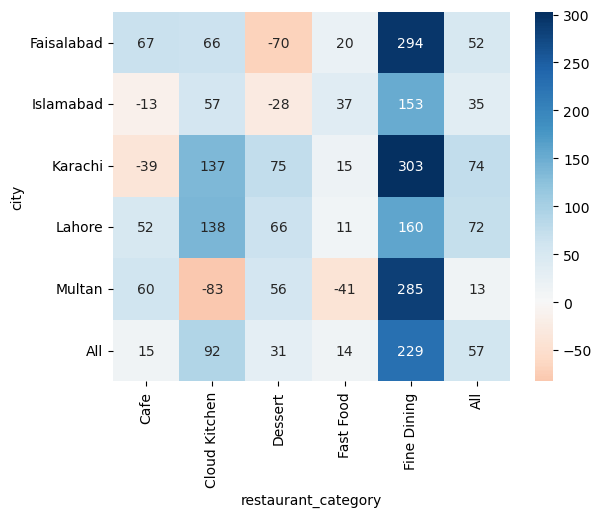

In [13]:
#task5
profit_pivot = pd.pivot_table(df, index='city', columns='restaurant_category', values='profit_per_order', aggfunc='mean', margins=True)
sns.heatmap(profit_pivot, annot=True, fmt='.0f', cmap='RdBu', center=0)
plt.show()
# Karachi x Fine Dining is the most profitable combination per order (~303). Lahore x Cloud Kitchen is the top revenue generator, so highest revenue and highest per-order profitability point to different combinations.

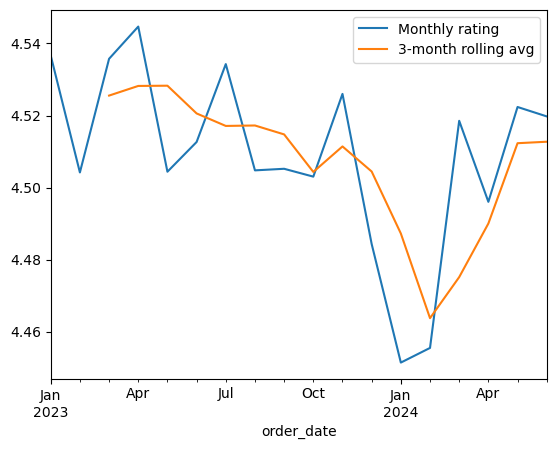

In [8]:
ts = df.set_index('order_date')
monthly = ts['rating'].resample('ME').mean()
rolling = monthly.rolling(window=3).mean()

monthly.plot(label='Monthly rating')
rolling.plot(label='3-month rolling avg')
plt.legend()
plt.show()
# Once smoothed, average rating is roughly flat/stable over time; the raw monthly line is noisier and could mislead into seeing ups and downs that the rolling average shows are just short-term noise.

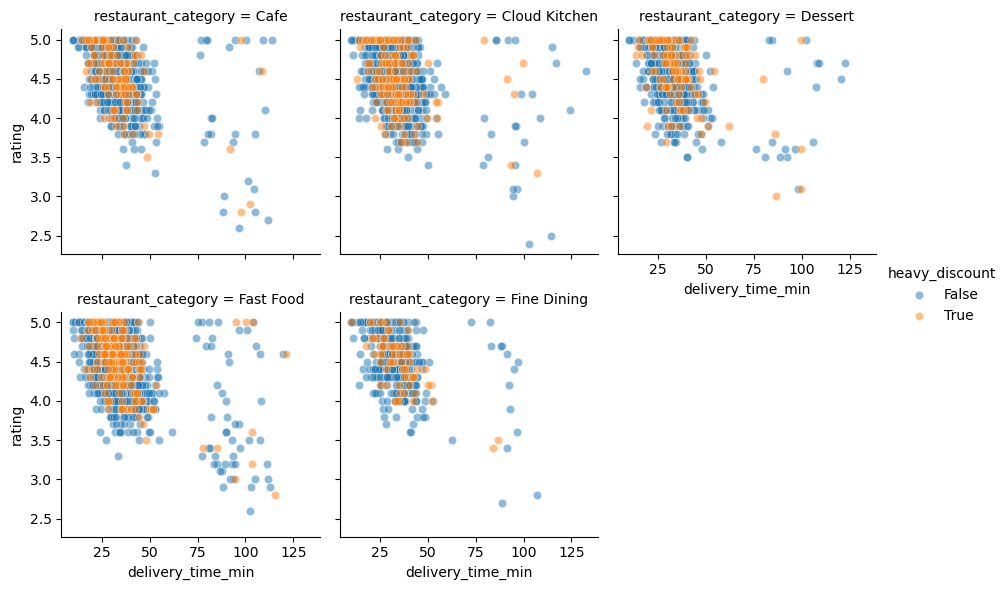

In [9]:
df['heavy_discount'] = df['discount_percent'] > 20
g = sns.FacetGrid(df, col='restaurant_category', hue='heavy_discount', col_wrap=3)
g.map(sns.scatterplot, 'delivery_time_min', 'rating', alpha=0.5)
g.add_legend()
plt.show()
# In Fine Dining, heavy discounting visibly changes tolerance: heavily discounted orders keep higher ratings even at longer delivery times, unlike non-discounted orders.

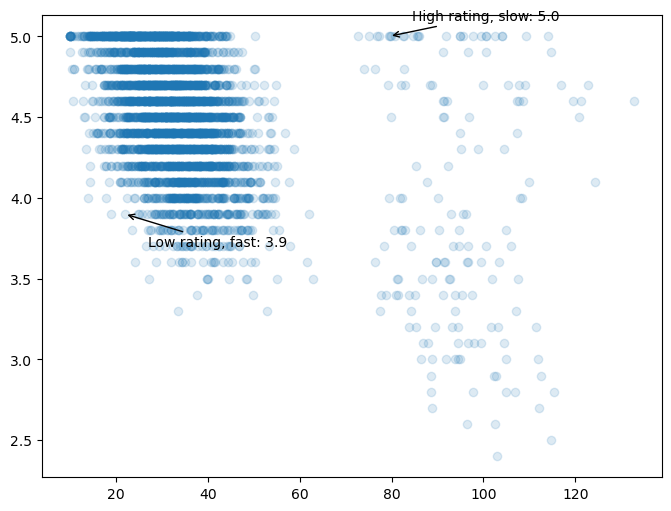

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df['delivery_time_min'], df['rating'], alpha=0.15)
# Alpha chosen over hexbin since dataset has ~4200 points (moderate overlap, not 50k+).

slow_orders = df[df['delivery_time_min'] > df['delivery_time_min'].quantile(0.9)]
best_despite_slow = slow_orders.loc[slow_orders['rating'].idxmax()]

fast_orders = df[df['delivery_time_min'] < df['delivery_time_min'].quantile(0.1)]
worst_despite_fast = fast_orders.loc[fast_orders['rating'].idxmin()]

ax.annotate(f"High rating, slow: {best_despite_slow['rating']}", xy=(best_despite_slow['delivery_time_min'], best_despite_slow['rating']),
            xytext=(best_despite_slow['delivery_time_min']+5, best_despite_slow['rating']+0.1), arrowprops=dict(arrowstyle='->'))
ax.annotate(f"Low rating, fast: {worst_despite_fast['rating']}", xy=(worst_despite_fast['delivery_time_min'], worst_despite_fast['rating']),
            xytext=(worst_despite_fast['delivery_time_min']+5, worst_despite_fast['rating']-0.2), arrowprops=dict(arrowstyle='->'))
plt.show()